# Digital options : pricing tests

European digital options of `Produits/products.py`:
- `DigitalOption`: cash-or-nothing (pays a fixed amount) or asset-or-nothing (pays $S_T$) call / put;
- `DigitalBarrierOption`: digital with a knock-in / knock-out barrier.

Digitals are European only: an "American" cash digital is a one-touch option, which is a barrier product.

1. Payoffs. 2. Validation against the Black formula in a flat market. 3. CAC40 under Heston, and the effect of
the skew. 4. Digital barriers. 5. Greeks.

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..", "Model")))   # models, Monte Carlo engine, Greeks
sys.path.append(os.path.abspath(".."))                                # Produits : products.py, market.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from market import cac40_heston, flat_market
from products import Exercise, VanillaOption, BarrierOption, DigitalOption, DigitalBarrierOption
from monte_carlo import MonteCarloPricer
from greeks import Greeks, bump_spot, plot_greeks_bars, plot_greek_profiles

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. Payoffs

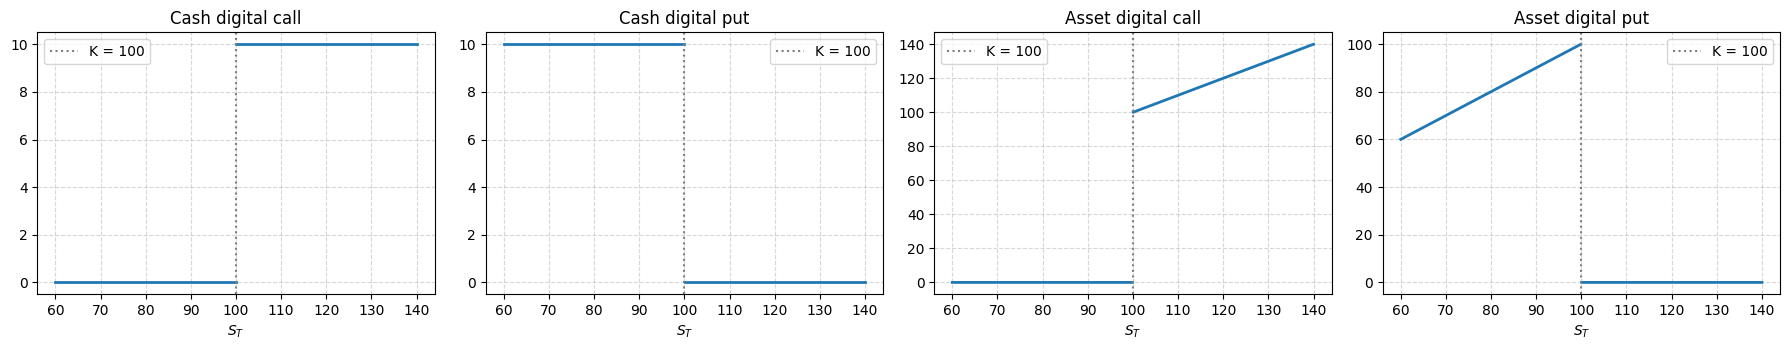

In [2]:
S = np.linspace(60, 140, 801)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
specs = [("Cash digital call", DigitalOption(100, 1.0, True, cash=10)), ("Cash digital put", DigitalOption(100, 1.0, False, cash=10)),
         ("Asset digital call", DigitalOption(100, 1.0, True, asset=True)), ("Asset digital put", DigitalOption(100, 1.0, False, asset=True))]
for ax, (title, option) in zip(axes, specs):
    payoff = option.payoff(S).astype(float)
    payoff[np.abs(S - 100) < 0.05] = np.nan          # do not draw the vertical jump at the strike
    ax.plot(S, payoff, linewidth=2)
    ax.axvline(100, color="grey", linestyle=":", label="K = 100")
    ax.set_title(title)
    ax.set_xlabel("$S_T$")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

## 2. Validation in a flat Black-Scholes market

Closed forms: cash-or-nothing $= \text{cash}\, D(T) N(\pm d_2)$, asset-or-nothing $= D(T) F(T) N(\pm d_1)$
(`BlackScholes.bs_price_digital`). The pricer without control variate is compared with them; the
"semi-analytical" column is $-\partial C / \partial K$ computed from the model vanilla prices, which is also the
exact price used by the control variate.

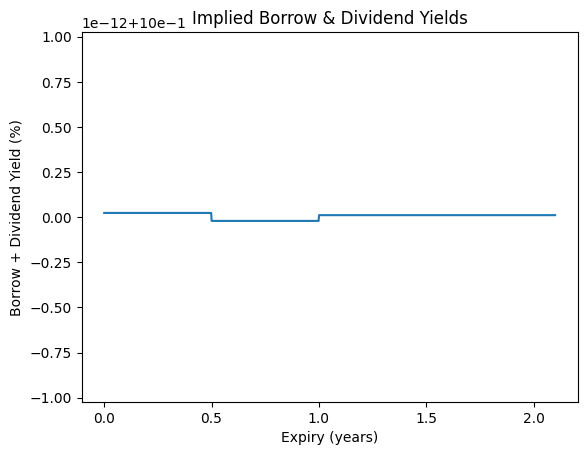

,Black,Semi-analytical,Monte Carlo,Std error,Error / std error
Option,,,,,
CashDigitalCall K=90,6.80122,6.80125,6.8002,0.0106372,-0.0954769
AssetDigitalCall K=90,75.8701,75.8698,75.8733,0.081581,0.0390319
CashDigitalPut K=90,2.90324,2.90321,2.90425,0.0106372,0.0954769
AssetDigitalPut K=90,23.1348,23.1352,23.1355,0.0857219,0.00747517
CashDigitalCall K=100,4.85223,4.85226,4.85232,0.000168087,0.577346
AssetDigitalCall K=100,57.3496,57.3493,57.3655,0.0330026,0.482112
CashDigitalPut K=100,4.85223,4.85219,4.85213,0.000168087,-0.577346
AssetDigitalPut K=100,41.6554,41.6557,41.6433,0.0212791,-0.567971
CashDigitalCall K=110,3.07477,3.07481,3.07515,0.0104546,0.0362228


In [3]:
flat = flat_market()
raw = MonteCarloPricer(n_paths=100_000, steps_per_year=252, seed=1, control_variate=False)
rows = []
for K in [90, 100, 110]:
    for isCall in [True, False]:
        for asset in [False, True]:
            option = DigitalOption(K, 1.0, isCall, cash=10, asset=asset)
            exact = flat.bs_model.bs_price_digital(1.0, K, flat.sigma, isCall, cash=10, asset=asset)
            mc = raw.price(flat.heston, option)
            rows.append({"Option": f"{option.code} K={K}", "Black": exact,
                         "Semi-analytical": option.exact_european_price(flat.heston),
                         "Monte Carlo": mc.price, "Std error": mc.stderr, "Error / std error": (mc.price - exact) / mc.stderr})
pd.DataFrame(rows).set_index("Option")

## 3. CAC40 under the calibrated Heston model

A digital is the derivative of the call price with respect to the strike, $-\partial C/\partial K$. With a smile,
$C(K) = C_{BS}(K, \sigma(K))$, so
$$
\text{Digital} = -\frac{\partial C_{BS}}{\partial K} - \mathcal{V}\,\frac{\partial \sigma}{\partial K}.
$$
With a negative skew ($\partial\sigma/\partial K < 0$), the digital call is worth **more** than the Black digital
computed with the implied volatility of its strike. The table compares the Heston price, the Monte Carlo price
and this Black digital.

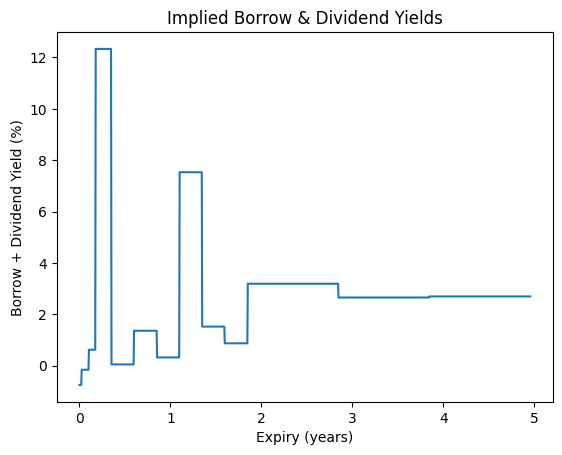

CAC40 2025-02-12 : S0 = 8042.19, 142 quotes on 13 expiries
Heston : v0=0.0197, theta=0.0438, kappa=1.3079, xi=0.4820, rho=-0.6050 | implied vol RMSE = 0.421 vol pts


In [4]:
mkt = cac40_heston()
heston, S0, T = mkt.heston, mkt.S0, 1.0
pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42)
raw = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42, control_variate=False)

In [5]:
cash = 1000.0
rows = []
for K in [7200, 7600, 8000, 8400, 8800]:
    for isCall in [True, False]:
        option = DigitalOption(K, T, isCall, cash=cash)
        mc = raw.price(heston, option)
        heston_price = option.exact_european_price(heston)
        black = mkt.bs_model.bs_price_digital(T, K, float(mkt.iv_surface.get_vol(T, K)), isCall, cash=cash)
        rows.append({"Option": f"{'Call' if isCall else 'Put'} K={K}", "Heston (from Lewis)": heston_price,
                     "Monte Carlo": mc.price, "Std error": mc.stderr,
                     "Black, smile vol at K": black, "Skew effect": heston_price - black})
pd.DataFrame(rows).set_index("Option")

,Heston (from Lewis),Monte Carlo,Std error,"Black, smile vol at K",Skew effect
Option,,,,,
Call K=7200,764.622,765.944,1.56323,687.264,77.358
Put K=7200,212.347,211.025,1.56323,289.705,-77.358
Call K=7600,677.236,676.727,1.63077,584.146,93.0898
Put K=7600,299.733,300.242,1.63077,392.823,-93.0898
Call K=8000,559.025,557.42,1.62664,466.373,92.6518
Put K=8000,417.945,419.55,1.62664,510.597,-92.6518
Call K=8400,411.867,410.562,1.61718,340.38,71.4868
Put K=8400,565.103,566.408,1.61718,636.589,-71.4868
Call K=8800,259.989,257.216,1.60849,225.963,34.026


## 4. Digital barrier options

Cash digital calls and puts (cash = 1000, K = 8000) with a down barrier at 7200 or an up barrier at 8800.
In / Out parity: knock-in + knock-out = digital. Continuous monitoring (Brownian bridge) against daily discrete
monitoring.

In [6]:
rows = []
for isCall in [True, False]:
    for direction, H in [("down", 7200.0), ("up", 8800.0)]:
        digital = DigitalOption(8000, T, isCall, cash=cash)
        prices = {}
        for knock in ["in", "out"]:
            option = DigitalBarrierOption(8000, T, H, isCall, direction, knock, cash=cash)
            discrete = DigitalBarrierOption(8000, T, H, isCall, direction, knock, cash=cash, monitoring="discrete")
            res = pricer.price(heston, option)
            prices[knock] = res.price
            rows.append({"Option": option.code, "H": H, "Price": res.price, "Std error": res.stderr,
                         "Price (discrete)": pricer.price(heston, discrete).price})
        rows.append({"Option": f"in + out vs digital {'call' if isCall else 'put'}", "H": H,
                     "Price": prices["in"] + prices["out"], "Std error": np.nan,
                     "Price (discrete)": digital.exact_european_price(heston)})
pd.DataFrame(rows).set_index("Option")

,H,Price,Std error,Price (discrete)
Option,,,,
CDI-CashDigital,7200,113.374,1.23823,97.7431
CDO-CashDigital,7200,445.651,1.23824,461.281
in + out vs digital call,7200,559.025,NaN,559.025
CUI-CashDigital,8800,377.383,1.44614,365.204
CUO-CashDigital,8800,181.641,1.44613,193.821
in + out vs digital call,8800,559.025,NaN,559.025
PDI-CashDigital,7200,350.936,1.00523,340.651
PDO-CashDigital,7200,67.0091,1.00523,77.2941
in + out vs digital put,7200,417.945,NaN,417.945


## 5. Greeks

With the control variate, a European digital is priced exactly (its control variate is itself), so its Greeks
are those of the semi-analytical price. The Monte Carlo Greeks, without control variate, are compared with them:
the payoff jumps at the strike, so Gamma and Vanna are much noisier than for a vanilla.

In [7]:
option = DigitalOption(8000, T, True, cash=cash)
start = time.time()
comparison = pd.concat({"Semi-analytical": Greeks(pricer).compute(heston, option)["value"],
                        "Monte Carlo": Greeks(raw).compute(heston, option)["value"],
                        "MC std error": Greeks(raw).compute(heston, option)["stderr"]}, axis=1)
print(f"{time.time() - start:.1f}s")
comparison

14.5s


,Semi-analytical,Monte Carlo,MC std error
price,559.025,557.42,1.62664
delta,0.334297,0.336501,0.00626678
gamma,-0.00027431,-0.000320235,0.00015882
vega,-6.08616,-6.01813,0.382004
vanna,-0.024008,-0.0252072,0.0031281
volga,0.277276,0.195394,0.861524
rho,21.2921,21.2887,1.61722
theta,-0.021872,-0.0458948,0.0829006


47.4s


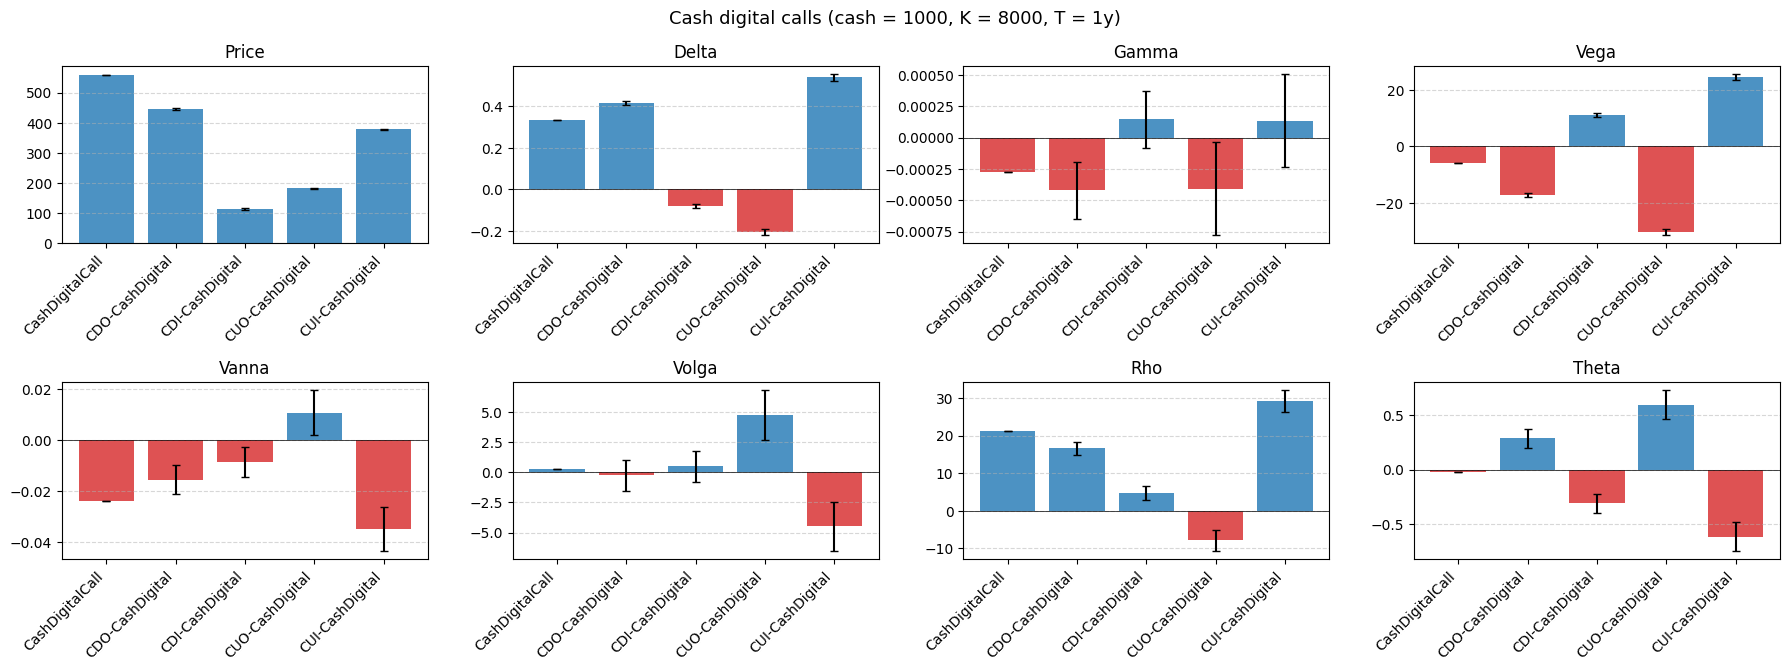

,price,delta,gamma,vega,vanna,volga,rho,theta
CashDigitalCall,559.025,0.334297,-0.00027431,-6.08616,-0.024008,0.277276,21.2921,-0.021872
CDO-CashDigital,445.651,0.414937,-0.000418924,-17.2156,-0.0154817,-0.244731,16.587,0.28691
CDI-CashDigital,113.374,-0.0806398,0.000144614,11.1295,-0.00852632,0.522007,4.70507,-0.308782
CUO-CashDigital,181.641,-0.204723,-0.000407952,-30.4961,0.0108985,4.77373,-7.86557,0.597174
CUI-CashDigital,377.383,0.53902,0.000133642,24.4099,-0.0349065,-4.49646,29.1577,-0.619046


In [8]:
barrier_digitals = [DigitalBarrierOption(8000, T, 7200.0, True, "down", "out", cash=cash),
                    DigitalBarrierOption(8000, T, 7200.0, True, "down", "in", cash=cash),
                    DigitalBarrierOption(8000, T, 8800.0, True, "up", "out", cash=cash),
                    DigitalBarrierOption(8000, T, 8800.0, True, "up", "in", cash=cash)]
start = time.time()
digital_greeks = Greeks(pricer).table(heston, [option] + barrier_digitals, with_stderr=True)
print(f"{time.time() - start:.1f}s")
plot_greeks_bars(digital_greeks, title="Cash digital calls (cash = 1000, K = 8000, T = 1y)");
digital_greeks[[c for c in digital_greeks.columns if not c.endswith("stderr")]]

63.3s


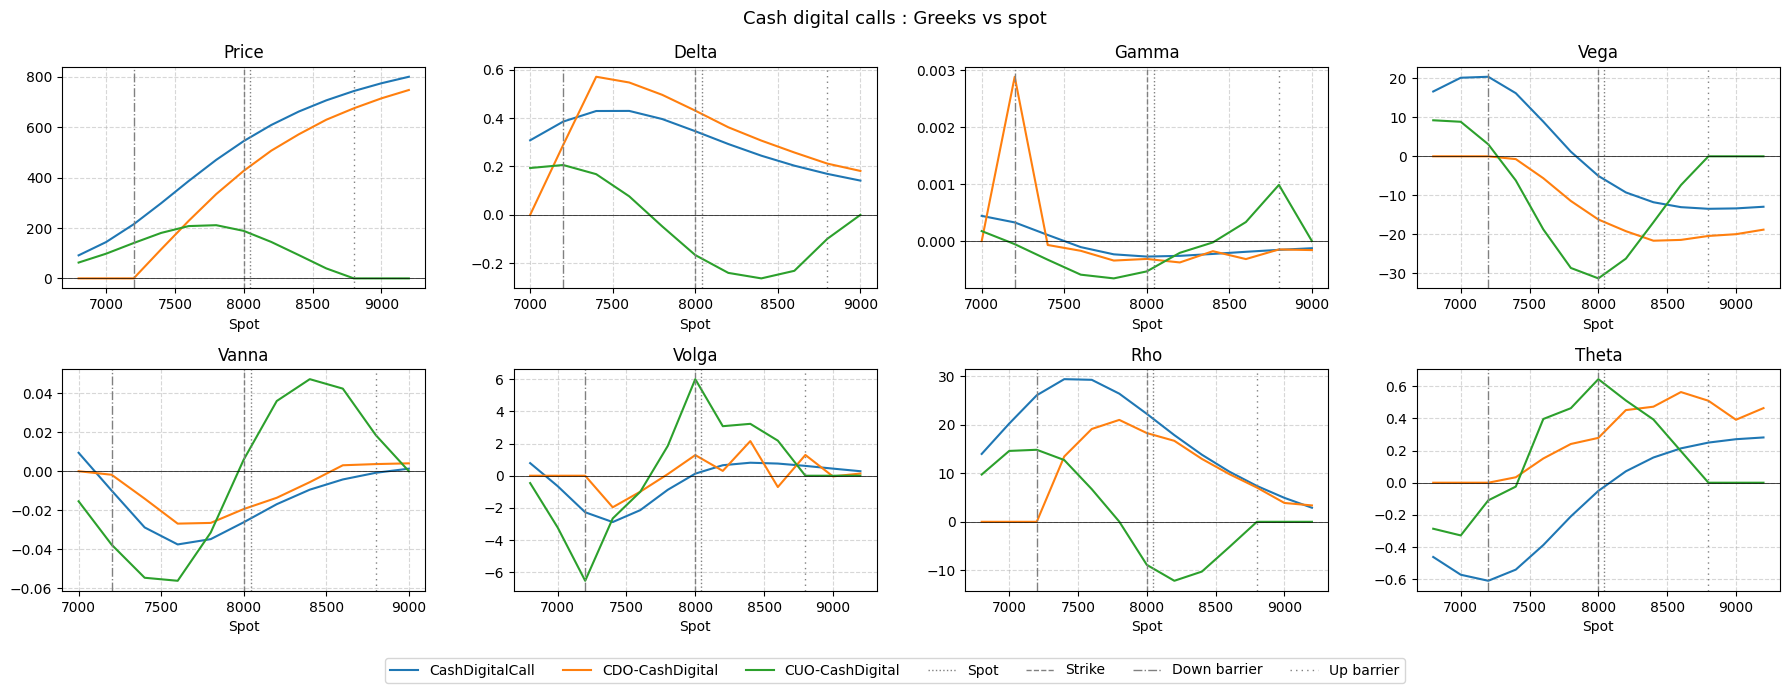

In [9]:
profile_pricer = MonteCarloPricer(n_paths=30_000, steps_per_year=252, seed=42)
start = time.time()
profiles = Greeks(profile_pricer).profiles(heston, [option] + barrier_digitals[::2], np.arange(6800.0, 9201.0, 200.0))
print(f"{time.time() - start:.1f}s")
plot_greek_profiles(profiles, vlines={"Spot": S0, "Strike": 8000, "Down barrier": 7200, "Up barrier": 8800},
                    title="Cash digital calls : Greeks vs spot");